# 05 · Variables

**Principe** : le soir du jour J, l'exploitant prépare la tournée du lendemain. Le modèle ne peut utiliser **que ce qui est connu ce soir-là** : les sessions de J et des jours précédents, la météo observée de J, et le calendrier de J+1 (connu à l'avance). La cible est l'épisode du jour J+1.

```
     ... J-27 ... J-6 ... J-1   J   |  J+1
     <------ passé connu ------>    |  à prédire (épisode oui / non)
                         le soir de J : on calcule les variables
```

**Règle de sélection** : on ne regarde **que la période d'entraînement** (2020) pour choisir les variables. Regarder la validation ou le test pour choisir serait une fuite : on choisirait ce qui marche sur des données censées rester inconnues.

## Les familles de variables, leur hypothèse et leur piège

| Famille | Hypothèse : pourquoi elle pourrait prédire | Piège : comment elle pourrait tromper |
|---|---|---|
| Défauts récents (jour, 3, 7, 28 jours, tendance) | Une borne qui se dégrade montre des défauts croissants avant l'épisode | Désigner seulement les bornes chroniquement mauvaises ; la cible est relative, les variables brutes non |
| Épisodes passés | Les épisodes arrivent en série (persistance de 23 %) | Rendre le modèle équivalent à la règle « épisode aujourd'hui » |
| Signaux faibles (sessions vides, très courtes, défauts véhicule) | Des recharges ratées ou des défauts mal attribués précèdent une panne franche | La part de sessions vides dérive dans le temps (6 à 17 % selon les mois) |
| Usage (sessions, tendance, jours sans session, âge) | Plus de sollicitations, plus d'usure ; une borne délaissée est peut-être déjà en panne | Plus d'usage, mécaniquement plus de défauts, sans dégradation réelle ; le volume double sur la période |
| Calendrier du jour prédit | Fêtes et week-ends changent l'usage | Peu de fêtes dans l'entraînement : risque d'apprendre du bruit |
| Météo du jour J | Chaleur et pluie peuvent dégrader l'électronique | Météo journalière et par district : signal grossier |
| Site | Environnements différents (autoroute, gare, parc) | Le modèle mémorise des sites au lieu d'apprendre des comportements |

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

from evrel.data.clean import load_interim
from evrel.data.load import get_data_dir, load_weather
from evrel.features import FEATURE_GROUPS, NUMERIC_FEATURES, build_features
from evrel.split import assign_split
from evrel.viz import INK_2, NEUTRAL, PALETTE, set_style

set_style()
daily_target = pd.read_parquet(get_data_dir() / "processed" / "daily_target.parquet")
feats = build_features(daily_target, load_interim(), load_weather())
feats["split"] = assign_split(feats["target_date"])
print(f"{len(feats):,} lignes (borne, jour J) avec une cible observable en J+1, {len(NUMERIC_FEATURES)} variables")

57,678 lignes (borne, jour J) avec une cible observable en J+1, 27 variables


## 1. Les périodes du découpage

Chaque ligne est rangée selon la date du jour **prédit** (J+1). Ainsi, la dernière ligne d'entraînement prédit le 31 décembre 2020, et aucune cible de la validation ne sert à l'entraînement.

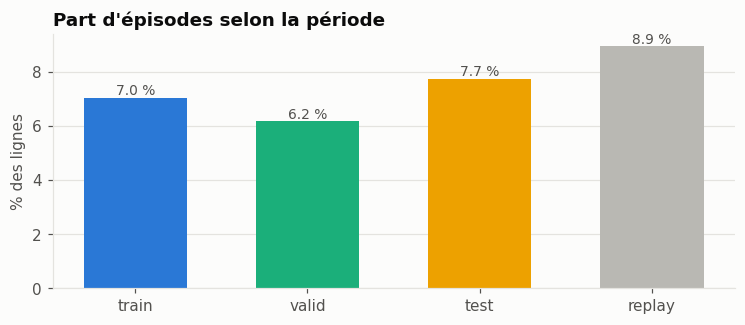

,lignes,épisodes,taux_pct,du,au
split,,,,,
train,26860,1890.0,7.04,2020-01-08,2020-12-31
valid,9760,602.0,6.17,2021-01-01,2021-04-30
test,10579,818.0,7.73,2021-05-01,2021-08-31
replay,10479,936.0,8.93,2021-09-01,2021-12-31


In [4]:
by_split = (feats.groupby("split", sort=False)
            .agg(lignes=("y", "size"), épisodes=("y", "sum"), taux_pct=("y", "mean"),
                 du=("target_date", "min"), au=("target_date", "max"))
            .reindex(["train", "valid", "test", "replay"]))
by_split["taux_pct"] = (by_split["taux_pct"] * 100).round(2)

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(by_split.index, by_split["taux_pct"], color=[PALETTE[0], PALETTE[2], PALETTE[3], NEUTRAL], width=0.6)
for x, v in enumerate(by_split["taux_pct"]):
    ax.text(x, v, f"{v:.1f} %", ha="center", va="bottom", fontsize=9, color=INK_2)
ax.set_title("Part d'épisodes selon la période")
ax.set_ylabel("% des lignes")
ax.grid(axis="x", visible=False)
plt.show()
by_split

**Constat** : 56 673 lignes, rangées selon la date du jour prédit. Entraînement : 26 860 lignes et 7,04 % d'épisodes ; validation : 9 434 lignes et 6,08 % ; test : 10 237 lignes et 7,75 % ; production simulée : 10 142 lignes et 8,90 %.


## 2. Vérification de l'absence de fuite, sur un exemple

Pour une borne et une semaine, on vérifie à l'œil que la cible `y` du jour J est bien l'épisode de J+1, et que les variables de J ne contiennent rien du lendemain. Un test automatique le vérifie aussi (`test_no_leakage_from_the_future`).

In [5]:
post = feats.loc[feats["y"].eq(1), "post_id"].value_counts().index[0]
example = feats[feats["post_id"] == post].copy()
start = example.loc[example["y"].eq(1), "date"].iloc[0] - pd.Timedelta(days=3)
example = example[example["date"].between(start, start + pd.Timedelta(days=6))]
example[["date", "target_date", "hw_faults_d0", "hw_faults_3d", "hw_rate_7d", "episode_d0", "y"]]

,date,target_date,hw_faults_d0,hw_faults_3d,hw_rate_7d,episode_d0,y
11639,2020-01-07,2020-01-08,1,1.0,0.068966,0.0,0.0
11640,2020-01-08,2020-01-09,1,2.0,0.096154,0.0,1.0
11641,2020-01-09,2020-01-10,2,4.0,0.107143,1.0,0.0
11642,2020-01-10,2020-01-11,0,3.0,0.072727,0.0,0.0
11643,2020-01-11,2020-01-12,1,3.0,0.086207,0.0,0.0


**Constat** : sur l'exemple, `y` de chaque ligne est bien égal à `episode_d0` de la ligne suivante : la ligne du 8 janvier 2020 a `y = 1`, et le 9 janvier est bien un épisode. Les variables du jour J ne contiennent que des informations du jour J et des jours précédents. Le test `test_no_leakage_from_the_future` le vérifie automatiquement.

## 3. Valeurs manquantes (entraînement)

In [6]:
train = feats[feats["split"] == "train"]
missing = (train[NUMERIC_FEATURES].isna().mean() * 100).round(2)
missing[missing > 0].sort_values(ascending=False).to_frame("manquants %")

,manquants %
hw_rate_7d,0.66
hw_rate_trend,0.66
empty_share_7d,0.66
short_share_7d,0.66
vehicle_rate_7d,0.66


**Constat** : seules les variables calculées comme un taux sur 7 jours sont manquantes, dans 0,66 % des lignes : la borne n'a eu aucune session sur la semaine, la division est impossible.


## 4. Quelles variables séparent les jours avant épisode des autres ?

L'**AUC univariée** mesure, pour une variable seule, sa capacité à classer les jours qui précèdent un épisode au-dessus des autres :
- 0,5 = aucune information (comme tirer à pile ou face) ;
- 1,0 = séparation parfaite ;
- en dessous de 0,5 = la variable fonctionne « à l'envers » (une valeur basse annonce l'épisode).

On affiche donc l'écart à 0,5, quel que soit le sens. Calcul sur l'entraînement uniquement.

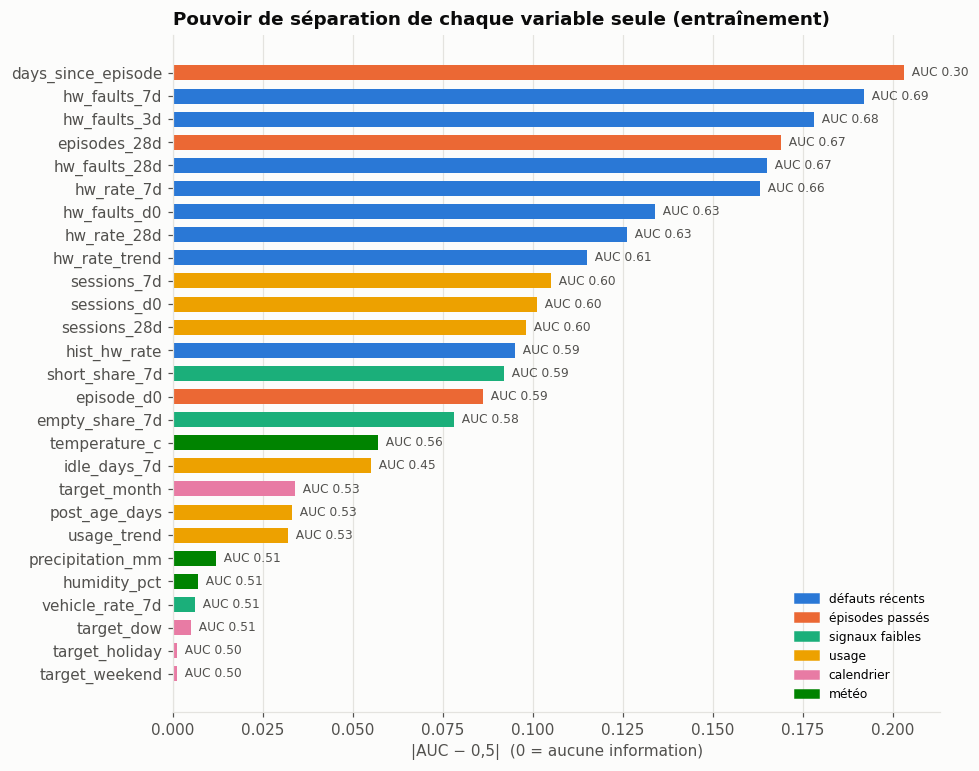

,variable,famille,AUC,force
0,days_since_episode,épisodes passés,0.297,0.203
1,hw_faults_7d,défauts récents,0.692,0.192
2,hw_faults_3d,défauts récents,0.678,0.178
3,episodes_28d,épisodes passés,0.669,0.169
4,hw_faults_28d,défauts récents,0.665,0.165
5,hw_rate_7d,défauts récents,0.663,0.163
6,hw_faults_d0,défauts récents,0.634,0.134
7,hw_rate_28d,défauts récents,0.626,0.126
8,hw_rate_trend,défauts récents,0.615,0.115
9,sessions_7d,usage,0.605,0.105


In [7]:
rows = []
for f in NUMERIC_FEATURES:
    ok = train[f].notna()
    auc = roc_auc_score(train.loc[ok, "y"], train.loc[ok, f])
    group = next(g for g, cols in FEATURE_GROUPS.items() if f in cols)
    rows.append({"variable": f, "famille": group, "AUC": round(auc, 3), "force": round(abs(auc - 0.5), 3)})
power = pd.DataFrame(rows).sort_values("force")

group_colors = {g: PALETTE[i] for i, g in enumerate(FEATURE_GROUPS)}
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(power["variable"], power["force"], color=power["famille"].map(group_colors), height=0.65)
for y, (v, a) in enumerate(zip(power["force"], power["AUC"])):
    ax.text(v, y, f"  AUC {a:.2f}", va="center", fontsize=8, color=INK_2)
ax.set_title("Pouvoir de séparation de chaque variable seule (entraînement)")
ax.set_xlabel("|AUC − 0,5|  (0 = aucune information)")
ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in group_colors.values()]
ax.legend(handles, group_colors.keys(), loc="lower right", fontsize=8)
plt.show()
power.sort_values("force", ascending=False).reset_index(drop=True)

**Constat** : les variables du passé récent de la borne dominent : jours depuis le dernier épisode (AUC 0,297, à lire à l'envers), pannes sur 7 jours (0,692), sur 3 jours (0,678), épisodes sur 28 jours (0,669). L'usage arrive ensuite (environ 0,60), puis les signaux faibles (sessions très courtes 0,592, sessions vides 0,578). Le calendrier n'apporte rien (0,499 à 0,505), comme la pluie, l'humidité et la part de défauts véhicule (0,506 à 0,512).


## 5. Le détail des meilleures variables

Taux d'épisode le lendemain selon le niveau de la variable (5 groupes de taille égale, du plus bas au plus haut). Une variable utile montre une pente nette.

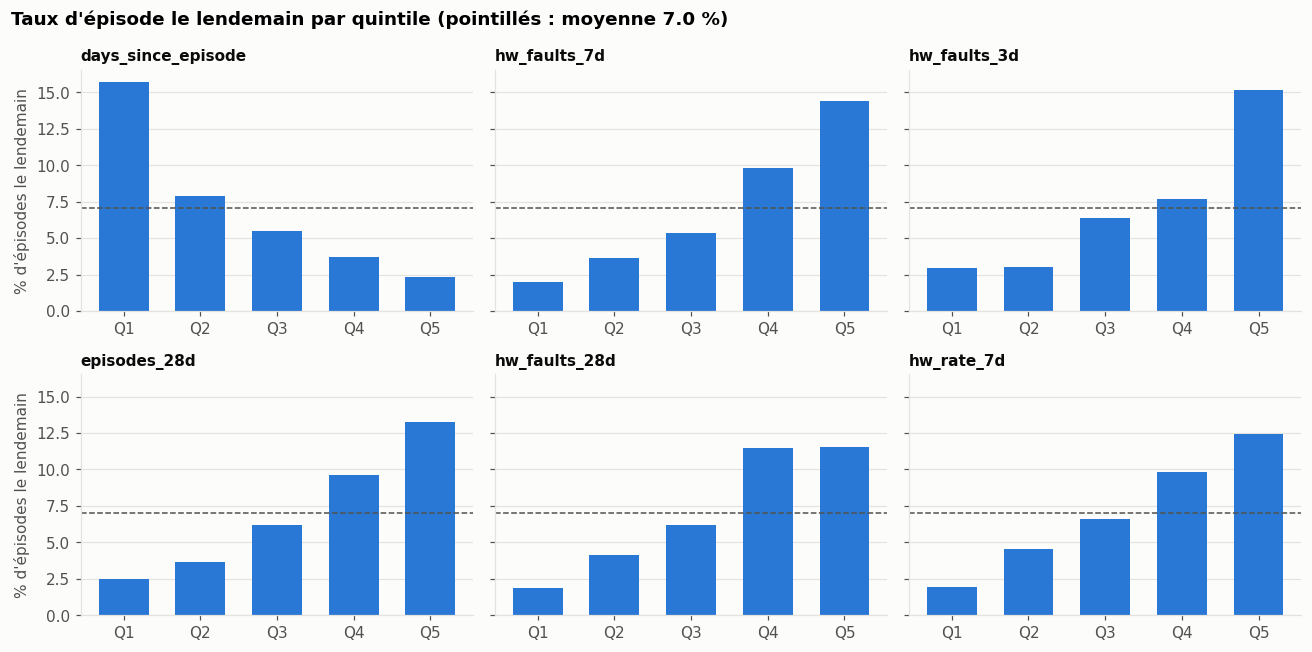

In [8]:
top = power.sort_values("force", ascending=False)["variable"].head(6).tolist()
base = train["y"].mean() * 100

fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharey=True)
for ax, f in zip(axes.ravel(), top):
    bins = pd.qcut(train[f].rank(method="first"), 5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"])
    rate = train.groupby(bins, observed=True)["y"].mean() * 100
    ax.bar(rate.index.astype(str), rate.values, color=PALETTE[0], width=0.65)
    ax.axhline(base, color=INK_2, lw=1, ls="--")
    ax.set_title(f, fontsize=10)
    ax.grid(axis="x", visible=False)
for ax in axes[:, 0]:
    ax.set_ylabel("% d'épisodes le lendemain")
fig.suptitle(f"Taux d'épisode le lendemain par quintile (pointillés : moyenne {base:.1f} %)", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

**Constat** : les pentes sont nettes et régulières. Après un épisode très récent, le risque d'épisode le lendemain atteint 15,7 %, contre 2,3 % quand le dernier épisode est lointain. Les 20 % de jours avec le plus de pannes sur 7 jours ont 14,4 % de risque, contre 2,0 % pour les 20 % les plus calmes, soit un rapport de 7.


## 6. Redondance entre variables

Deux variables très corrélées apportent presque la même information. Ce n'est pas grave pour un modèle à base d'arbres, mais c'est utile à savoir pour l'interprétation et pour un modèle linéaire.

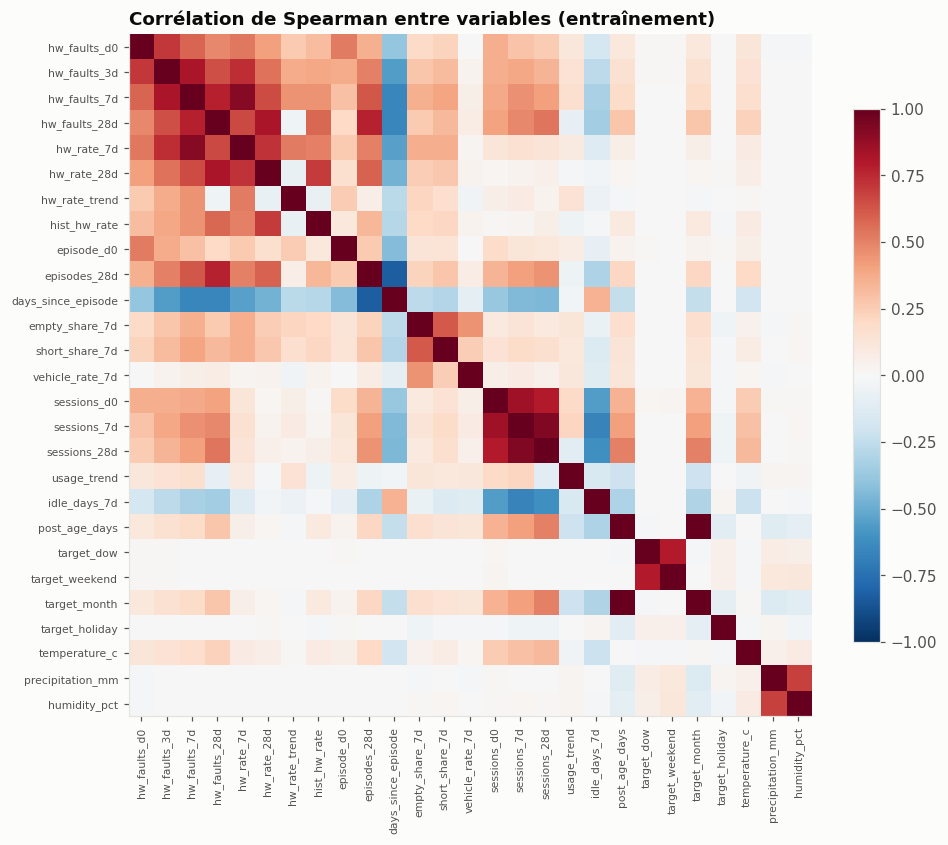

,level_0,level_1,corrélation
325,post_age_days,target_month,0.995582
285,sessions_7d,sessions_28d,0.928543
52,hw_faults_7d,hw_rate_7d,0.910312
273,sessions_d0,sessions_7d,0.851482


In [9]:
corr = train[NUMERIC_FEATURES].corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.index, fontsize=7)
ax.grid(False)
ax.set_title("Corrélation de Spearman entre variables (entraînement)")
fig.colorbar(im, ax=ax, shrink=0.7)
plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("corrélation").reset_index())
pairs[pairs["corrélation"].abs() >= 0.85].sort_values("corrélation", ascending=False)

**Constat** : quatre paires dépassent 0,85 de corrélation : âge de la borne et mois (0,996), sessions sur 7 et 28 jours (0,929), pannes et taux de pannes sur 7 jours (0,910), sessions du jour et sur 7 jours (0,851).


## 7. Calendrier et site

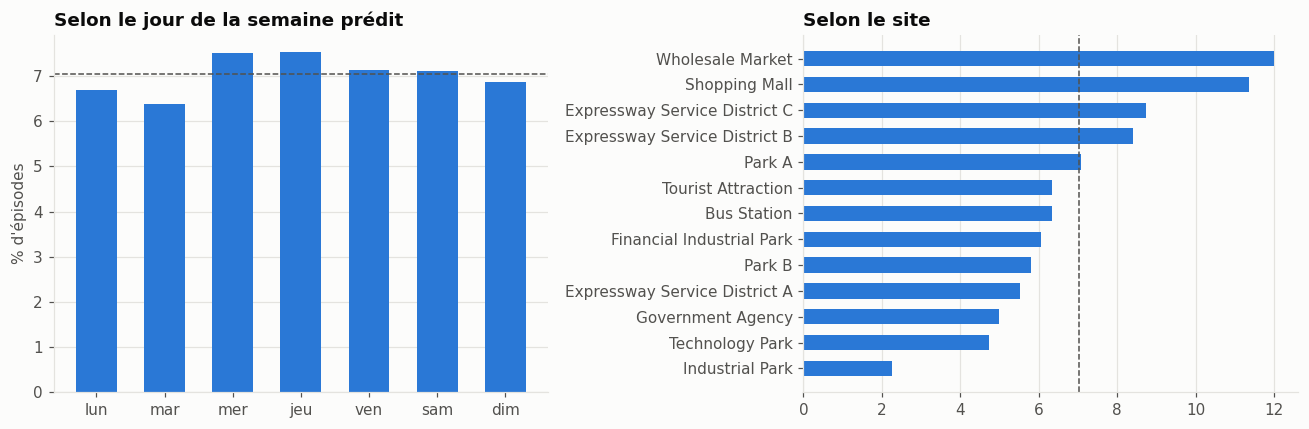

,lignes,épisodes %
target_holiday,,
jour ordinaire,24930,7.02
jour férié,1930,7.25


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
dow = train.groupby("target_dow")["y"].mean() * 100
axes[0].bar(["lun", "mar", "mer", "jeu", "ven", "sam", "dim"], dow.values, color=PALETTE[0], width=0.6)
axes[0].axhline(base, color=INK_2, lw=1, ls="--")
axes[0].set_title("Selon le jour de la semaine prédit")
axes[0].set_ylabel("% d'épisodes")

site = (train.groupby("site")["y"].mean() * 100).sort_values()
axes[1].barh(site.index, site.values, color=PALETTE[0], height=0.6)
axes[1].axvline(base, color=INK_2, lw=1, ls="--")
axes[1].set_title("Selon le site")
for ax in axes:
    ax.grid(axis="y" if ax is axes[1] else "x", visible=False)
plt.tight_layout()
plt.show()

hol = train.groupby("target_holiday")["y"].agg(["size", "mean"])
hol["mean"] = (hol["mean"] * 100).round(2)
hol.rename(index={0: "jour ordinaire", 1: "jour férié"}, columns={"size": "lignes", "mean": "épisodes %"})

**Constat** : le taux d'épisodes varie peu selon le jour prédit (de 6,4 à 7,5 %), et à peine les jours fériés (7,25 % contre 7,02 %). Il varie en revanche fortement selon le site : de 2,3 % à l'Industrial Park à 12 % au Wholesale Market.


## 8. Sauvegarde et décision

In [11]:
out = get_data_dir() / "processed" / "features.parquet"
feats.to_parquet(out, index=False)
print(f"Écrit : {out}  ({out.stat().st_size / 1e6:.1f} Mo, {feats.shape[0]:,} lignes × {feats.shape[1]} colonnes)")

Écrit : C:\dev\ev-reliability-data\processed\features.parquet  (2.1 Mo, 57,678 lignes × 34 colonnes)


**Décision** : 19 variables retenues sur 27 (`MODEL_FEATURES` dans `features.py`), choisies sur la période d'entraînement uniquement. Écartées : part de défauts véhicule, jour de la semaine, week-end, jour férié, pluie, humidité (aucune information), ainsi que le mois et l'âge de la borne (ils mesurent le temps qui passe). Le site sera testé avec et sans en phase 3.

## Ce qu'on retient

- **Le signal est dans l'historique de la borne** : épisode récent, pannes des 3 à 7 derniers jours. Après un épisode très récent, le risque du lendemain est de 15,7 %, contre 2,3 % sinon.
- **Le calendrier n'apporte rien** : la cible relative neutralise l'effet du volume.
- **Deux variables trompeuses écartées** : le mois et l'âge de la borne mesurent le temps, pas l'état de la borne.
- **La fréquence des épisodes monte** de 7,0 % (entraînement) à 8,9 % (production simulée) : dérive à surveiller.
- **Aucune fuite** : vérifiée à l'œil et par un test automatique.